In [9]:
# using python 3.9 environment

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.model_selection import train_test_split

import torch
from torchvision import datasets
from torchvision import transforms
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader

import os
import cv2

import glob 
import cuvis


In [10]:

def loadMeasurement(userSettingsDir, measurementLoc):

    # print("loading user settings...")
    settings = cuvis.General(userSettingsDir)
    # settings.set_log_level("info")

    # print("loading measurement file...")
    mesu = cuvis.Measurement(measurementLoc)
    # print("Data 1 {} t={}ms mode={}".format(mesu.name,mesu.integration_time,mesu.processing_mode.name,))

    # if not isinstance(mesu.MeasurementFlags, list):
    #     mesu.MeasurementFlags = [mesu.MeasurementFlags]

    # if isinstance(mesu.measurement_flags, cuvis.MeasurementFlags):
    #     print(f"Flags: {mesu.measurement_flags}")
    #     for v in cuvis.MeasurementFlags.supremum():
    #         print(f'{v}: {v in mesu.measurement_flags}')
    
    cube = mesu.data.get("cube", None)
    if cube is None:
        raise Exception("Cube not found")
    cube = cube.array
    # print(cube.shape)
    # cube_reshaped = cube.reshape(cube.shape[2], cube.shape[0], cube.shape[1])
    cube_result = np.transpose(cube, (2, 0, 1))
    # print(cube_result.shape)
    cube = cube_result
    if cube is None:
        raise Exception("Cube not found")
    
    # print("Cube shape: ", cube.shape)
    return cube

   



class AutoencoderDataset(Dataset):
    def __init__(self,  dataset_name, image_set,  root_dir, transform=None):
        self.dataset_name = dataset_name
        self.image_set = image_set
        self.transform = transform
        self.root = root_dir
        self.img_dir = root_dir
        self.img_names = [f for f in os.listdir(self.img_dir) if f.endswith('.' + 'cu3')]

        self.num_images = len( self.img_names  )

    def __getitem__(self, index):
        
        hyperspectral_image1 =self.root + self.img_names[index]
        # print(hyperspectral_image1)
        userSettingsDir = "/workspaces/HyperTools/settings/ultris20/" 
        hyperImage = loadMeasurement(userSettingsDir,hyperspectral_image1)
        data = hyperImage.astype(np.float32)

        return data

    def __len__(self):
        return self.num_images
    
        
# Creating a PyTorch class
# 28*28 ==> 9 ==> 28*28
class spectral_AE_threeD(torch.nn.Module):
    def __init__(self):
        super().__init__()

        # Building an linear encoder with Linear
        # layer followed by Relu activation function
        # 140 ==> 3
        self.encoder = torch.nn.Sequential(
            torch.nn.Linear(num_data_points, 64),
            torch.nn.ReLU(),
            torch.nn.Linear(64, 32),
            torch.nn.ReLU(),
            torch.nn.Linear(32, 16),
            torch.nn.ReLU(),
            torch.nn.Linear(16, 8),
            torch.nn.ReLU(),
            torch.nn.Linear(8, 3),
        )

        # Building an linear decoder with Linear
        # layer followed by Relu activation function
        # The Sigmoid activation function
        # outputs the value between 0 and 1
        # 3 ==> 140
        self.decoder = torch.nn.Sequential(
            torch.nn.Linear(3, 8),
            torch.nn.ReLU(),
            torch.nn.Linear(8, 16),
            torch.nn.ReLU(),
            torch.nn.Linear(16, 32),
            torch.nn.ReLU(),
            torch.nn.Linear(32, 64),
            torch.nn.ReLU(),
            torch.nn.Linear(64, num_data_points),
            torch.nn.Sigmoid()
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded    

def extract_rgb(cube, red_layer=78 , green_layer=40, blue_layer=25,  visualize=False):

  
    red_img = cube[ red_layer,:,:]
    green_img = cube[ green_layer,:,:]
    blue_img = cube[ blue_layer,:,:]

        
    data=np.stack([red_img,green_img,blue_img], axis=-1)
    # print(data.shape)
    #print(type(image))

    #convert to 8bit
    x_norm = (data-np.min(data))/(np.max(data)-np.min(data))
    image=(x_norm*255).astype('uint8')
    if visualize:
        #pass
        plt.imshow(image)
        plt.show()
    return image 

In [11]:
input_data_dir = "/workspaces/HyperImages/cornfields/session_002/" # need to reprocess this data

input_data_dir = "/workspaces/HyperImages/cornflakes_and_pasta/cornflakes_and_noodles_000/"



train_dataset = AutoencoderDataset(dataset_name='cornfields', root_dir=input_data_dir, image_set='train')



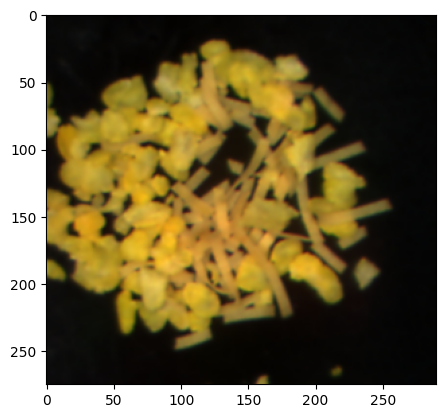

In [15]:
example= train_dataset[3]

# print(example.shape)

example1_image = extract_rgb(example, 31,13,2)
plt.imshow(example1_image)
plt.show()

num_data_points = example.shape[0] * example.shape[1] * example.shape[2]

In [13]:
spectral_model = spectral_AE_threeD()
train_loader = DataLoader(train_dataset, batch_size=2, shuffle=True)
test_loader = DataLoader(train_dataset, batch_size=1)


In [17]:
loss_function = torch.nn.L1Loss()
criterion = torch.nn.MSELoss()
device  = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# print (device)
spectral_model = spectral_model.to(device)
optimizer = torch.optim.Adam(spectral_model.parameters(),
                             lr = 1e-4,
                             weight_decay = 1e-5)

epochs = 2
history_loss_train = []
history_loss_val = []
for epoch in range(epochs):
    spectral_model.train()
    for inputs in train_loader:
        # print(inputs.shape)
        inputs = inputs.view(inputs.size(0), -1)  # Flatten the inputs

        inputs = inputs.float().to(device)
        outputs = spectral_model(inputs)
        loss = criterion(outputs, inputs)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    spectral_model.eval()
    with torch.no_grad():
        for inputs in test_loader:
            inputs = inputs.view(inputs.size(0), -1)  # Flatten the inputs

            inputs = inputs.float().to(device)
            outputs = spectral_model(inputs)
            val_loss = criterion(outputs, inputs)
    history_loss_train.append(loss.item())
    history_loss_val.append(val_loss.item())
    print(f'Epoch {epoch+1}/{epochs}, Loss: {loss.item()}, Validation Loss: {val_loss.item()}')

torch.Size([2, 51, 275, 290])
torch.Size([2, 51, 275, 290])
Epoch 1/2, Loss: 6743003.5, Validation Loss: 8249254.0
torch.Size([2, 51, 275, 290])
torch.Size([2, 51, 275, 290])
Epoch 2/2, Loss: 7843208.5, Validation Loss: 8249243.0
